# Computing time, memory, and computational cost

This notebook measures *observed wall-clock time on the executing machine*. A full spectral factorization is not universally faster: it incurs $\mathcal{O}(n^3)$ preprocessing and $\mathcal{O}(n^2)$ memory, whereas a banded solve can be efficient for one fit. Results are not transferable across machines.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## Machine metadata

Record system, CPU, Python, SciPy, NumPy, and thread-control variables. Results depend on BLAS, thermals, power mode, and concurrent programs.

In [2]:
import os,platform,sys,time
from math import comb
import numpy as np,scipy
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from trendestimation import TrendSmoother
for name,value in {"platform":platform.platform(),"processor":platform.processor(),"architecture":platform.machine(),"logical_cpus":os.cpu_count(),"python":sys.version.split()[0],"numpy":np.__version__,"scipy":scipy.__version__,"OPENBLAS_NUM_THREADS":os.environ.get("OPENBLAS_NUM_THREADS","unset"),"MKL_NUM_THREADS":os.environ.get("MKL_NUM_THREADS","unset")}.items():
    print(name,":",value)

platform : Linux-6.17.0-1022-azure-x86_64-with-glibc2.39
processor : x86_64
architecture : x86_64
logical_cpus : 4
python : 3.11.17
numpy : 2.4.6
scipy : 1.17.1
OPENBLAS_NUM_THREADS : 1
MKL_NUM_THREADS : 1


## Build the banded reference directly

For $d$ fixed, $Q=D_d^\top D_d$ is banded with half-bandwidth $d$. Here we accumulate each local outer product directly into the banded representation (no dense $n\times n$ matrix $Q$) and solve $(I+\lambda Q)\tau=y$ for $\mu=0$.

In [3]:
def banded_penalty(n,d):
    coeff=[(-1)**(d-j)*comb(d,j) for j in range(d+1)]
    ab=np.zeros((2*d+1,n))
    for r in range(n-d):
        for a,ca in enumerate(coeff):
            i=r+a
            for b,cb in enumerate(coeff):
                j=r+b
                ab[d+i-j,j]+=ca*cb
    return ab

def solve_trend_banded(y,bands,lam,d):
    ab=lam*bands.copy()
    ab[d]+=1
    return solve_banded((d,d),ab,y,overwrite_ab=True,check_finite=False)

def median_time(fn,reps=3):
    fn()
    times=[]
    for _ in range(reps):
        s=time.perf_counter();fn();times.append(time.perf_counter()-s)
    return float(np.median(times))

## Compare repeated smoothing

Compare total setup plus repeated fits, and validate parity against the structured solver. Small defaults keep documentation builds reasonable; manually use larger sizes for a serious benchmark.

In [4]:
sizes=[30,50,75] if os.environ.get("TRENDESTIMATION_FAST")=="1" else [40,70,100]
results=[]
for n in sizes:
    d=2;y=np.random.default_rng(120+n).normal(size=n)
    lambdas=np.geomspace(.001,1000,12)
    setup_s=median_time(lambda:TrendSmoother(n,d))
    sm=TrendSmoother(n,d)
    setup_b=median_time(lambda:banded_penalty(n,d))
    bands=banded_penalty(n,d)
    time_s=median_time(lambda:[sm.fit(y,lambda_=float(lam)).trend for lam in lambdas])
    time_b=median_time(lambda:[solve_trend_banded(y,bands,float(lam),d) for lam in lambdas])
    err=max(np.max(np.abs(sm.fit(y,lambda_=float(lam)).trend-solve_trend_banded(y,bands,float(lam),d))) for lam in lambdas)
    results.append((n,setup_s,time_s,setup_b,time_b,float(err)))
    print(f"n={n}: spectral={setup_s+time_s:.4g}s; banded={setup_b+time_b:.4g}s; max difference={err:.2e}")
assert max(r[-1] for r in results)<1e-6

n=30: spectral=0.0007036s; banded=0.0003049s; max difference=2.53e-14
n=50: spectral=0.0007578s; banded=0.0003582s; max difference=6.44e-14
n=75: spectral=0.001033s; banded=0.0004354s; max difference=4.60e-14


## Visualize runtime and theoretical storage

The $8n^2$-byte line is *analytical eigenvector storage*, not measured memory. Observe setup time separately from the 12 requested fits.

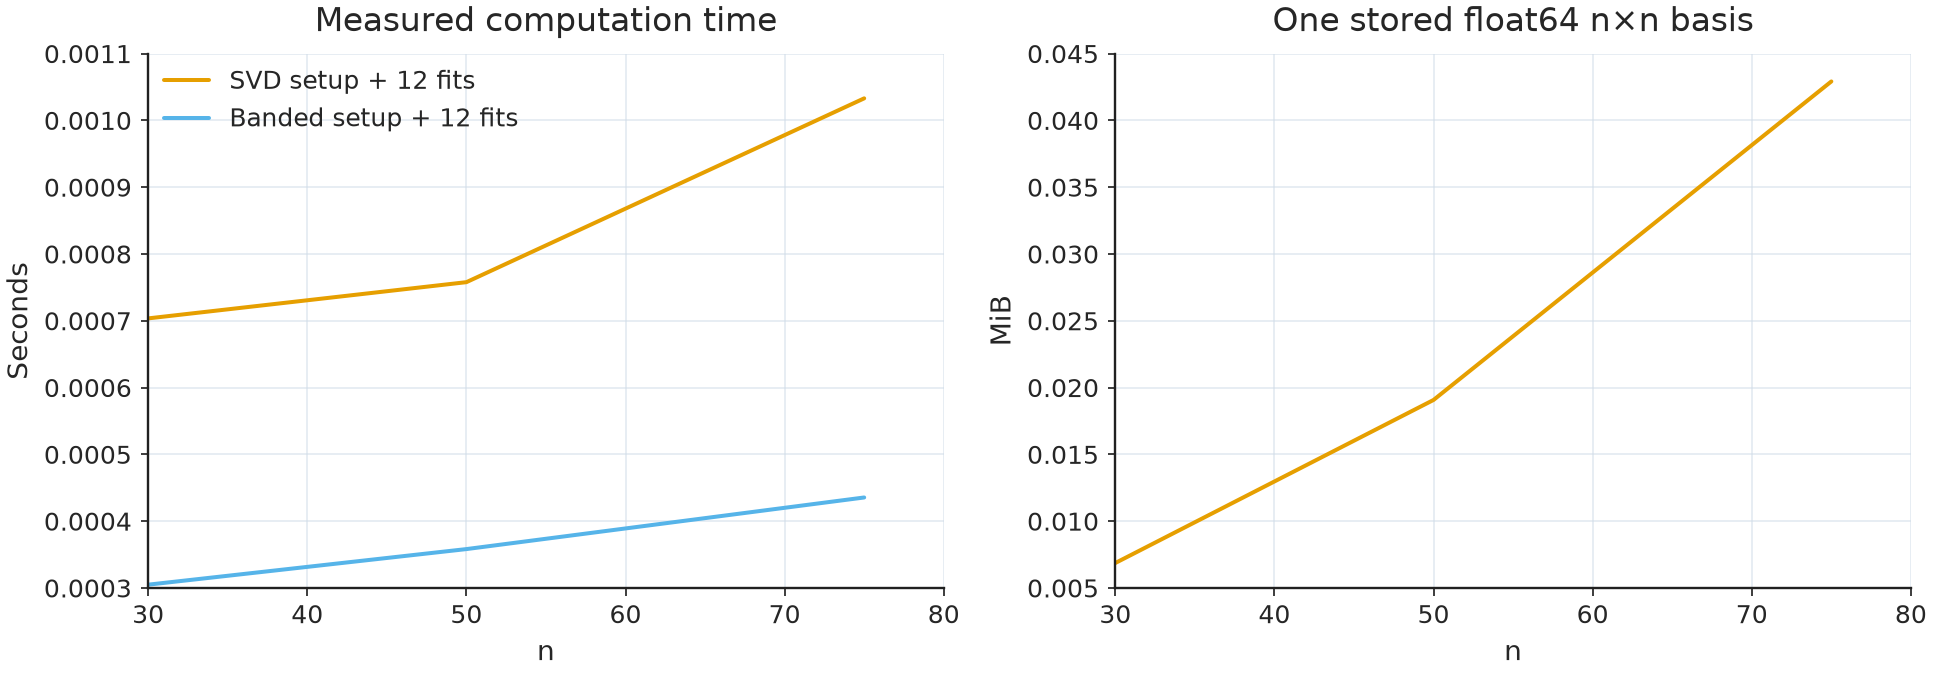

In [5]:
r=np.asarray(results)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(r[:,0],r[:,1]+r[:,2],"-",label="SVD setup + 12 fits")
axs[0].plot(r[:,0],r[:,3]+r[:,4],"-",label="Banded setup + 12 fits")
axs[0].set(xlabel="n",ylabel="Seconds",title="Measured computation time");axs[0].legend()
axs[1].plot(r[:,0],8*r[:,0]**2/1024**2,"-")
axs[1].set(xlabel="n",ylabel="MiB",title="One stored float64 n×n basis")
fig.tight_layout();plt.show()

## Optional MXN electricity estimates

Energy ≈ watts × elapsed seconds / (1000 × 3600) kWh; cost = energy × tariff in MXN/kWh. Neither value is an actual measurement until you provide independently measured power consumption.

In [6]:
assumed_system_watts=None   # edit on your own machine
tariff_mxn_per_kwh=None      # use a documented, actual electricity tariff
elapsed=sum(float(row[1]+row[2]) for row in results)
if assumed_system_watts is None or tariff_mxn_per_kwh is None:
    print("Energy/electricity cost not estimated: supply power and tariff.")
else:
    energy=assumed_system_watts*elapsed/(1000*3600)
    print(f"Assumed energy {energy:.7g} kWh; electricity {energy*tariff_mxn_per_kwh:.7g} MXN")

Energy/electricity cost not estimated: supply power and tariff.


## Matched penalty and smoothness score plots

For the current notebook data (or a labeled synthetic fallback), compare CV, GCV, AICc and BIC versus $\lambda$ **and** $S(\lambda)$; the mapped grids have identical candidate penalties. Each execution saves inline SVG and PNG figures. The single GCV selector timing is illustrative and is **not** a controlled speed comparison; use the separate multi-seed benchmark for that.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Paired coordinates: last 60 observations of the notebook series; n=60, d=2, mu=0
Normalized S grid: [0.       0.1      0.2      0.3      0.4      0.5      0.6      0.7
 0.8      0.9      0.95     0.99     0.999    0.9999   0.999999 1.      ]
S=0 maps to lambda=0; S=1 maps to lambda=+infinity.
Near-1 targets: S=0.950000 -> lambda=886.169, S=0.990000 -> lambda=33003.8, S=0.999000 -> lambda=510198, S=0.999900 -> lambda=5.29957e+06, S=0.999999 -> lambda=5.32145e+08
Maximum inversion / round-trip error: 1.33e-15


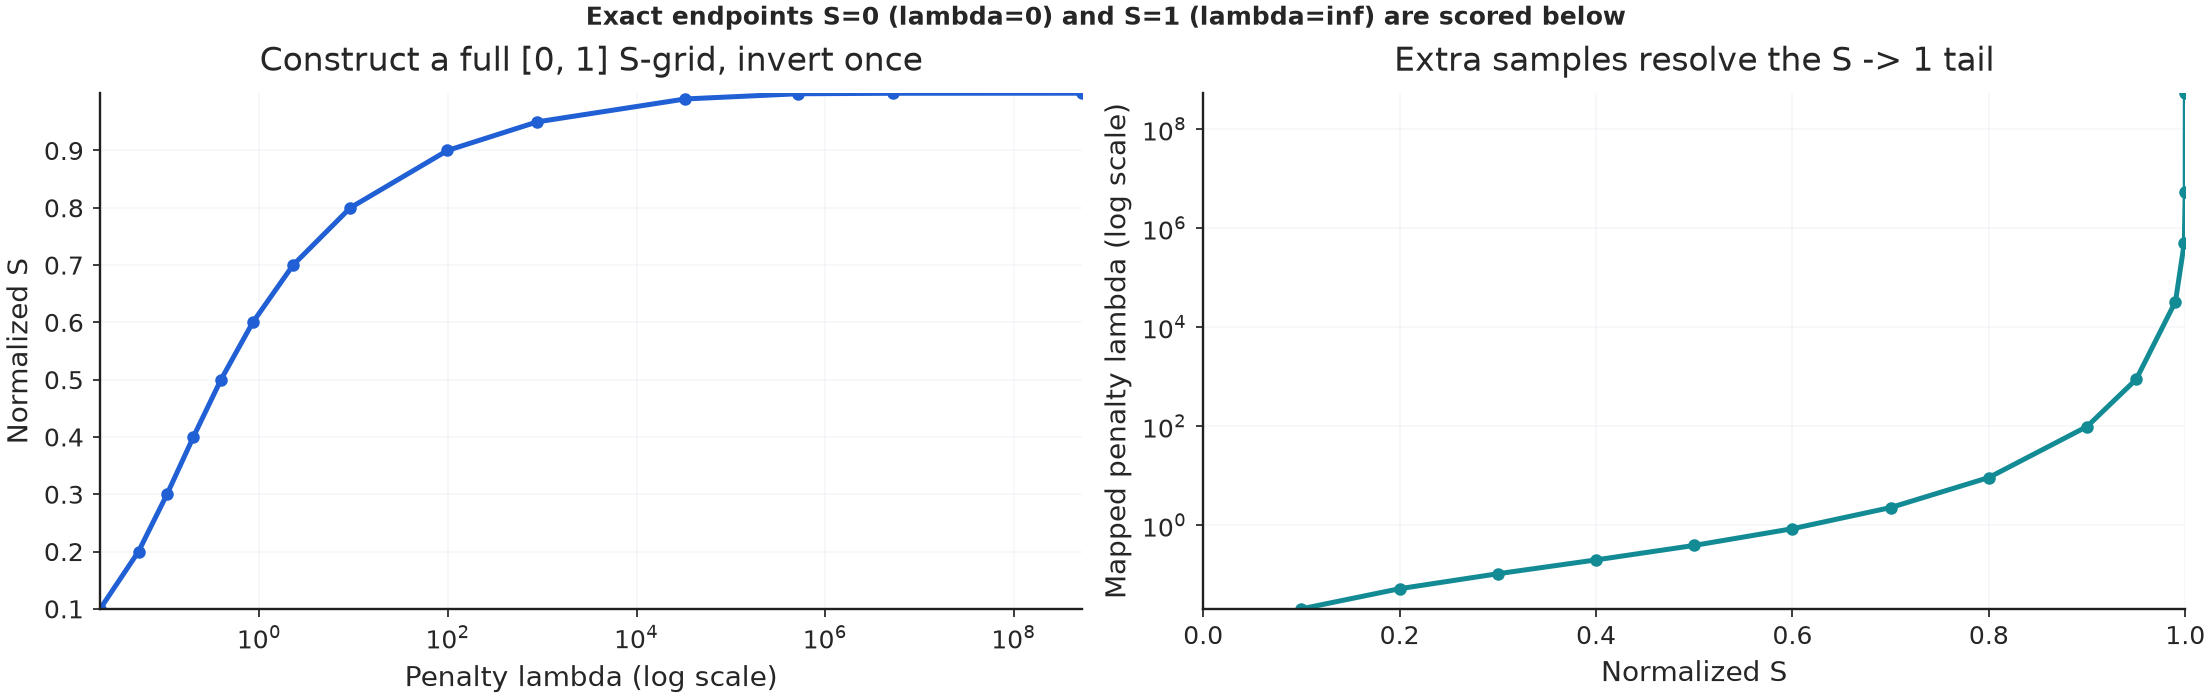

  CV: lambda=    886.169, S=0.95, score=0.91077
 GCV: lambda=    886.169, S=0.95, score=0.919947
AICC: lambda=        inf, S=1, score=-0.0506826
 BIC: lambda=  0.0205109, S=0.1, score=-0.536977


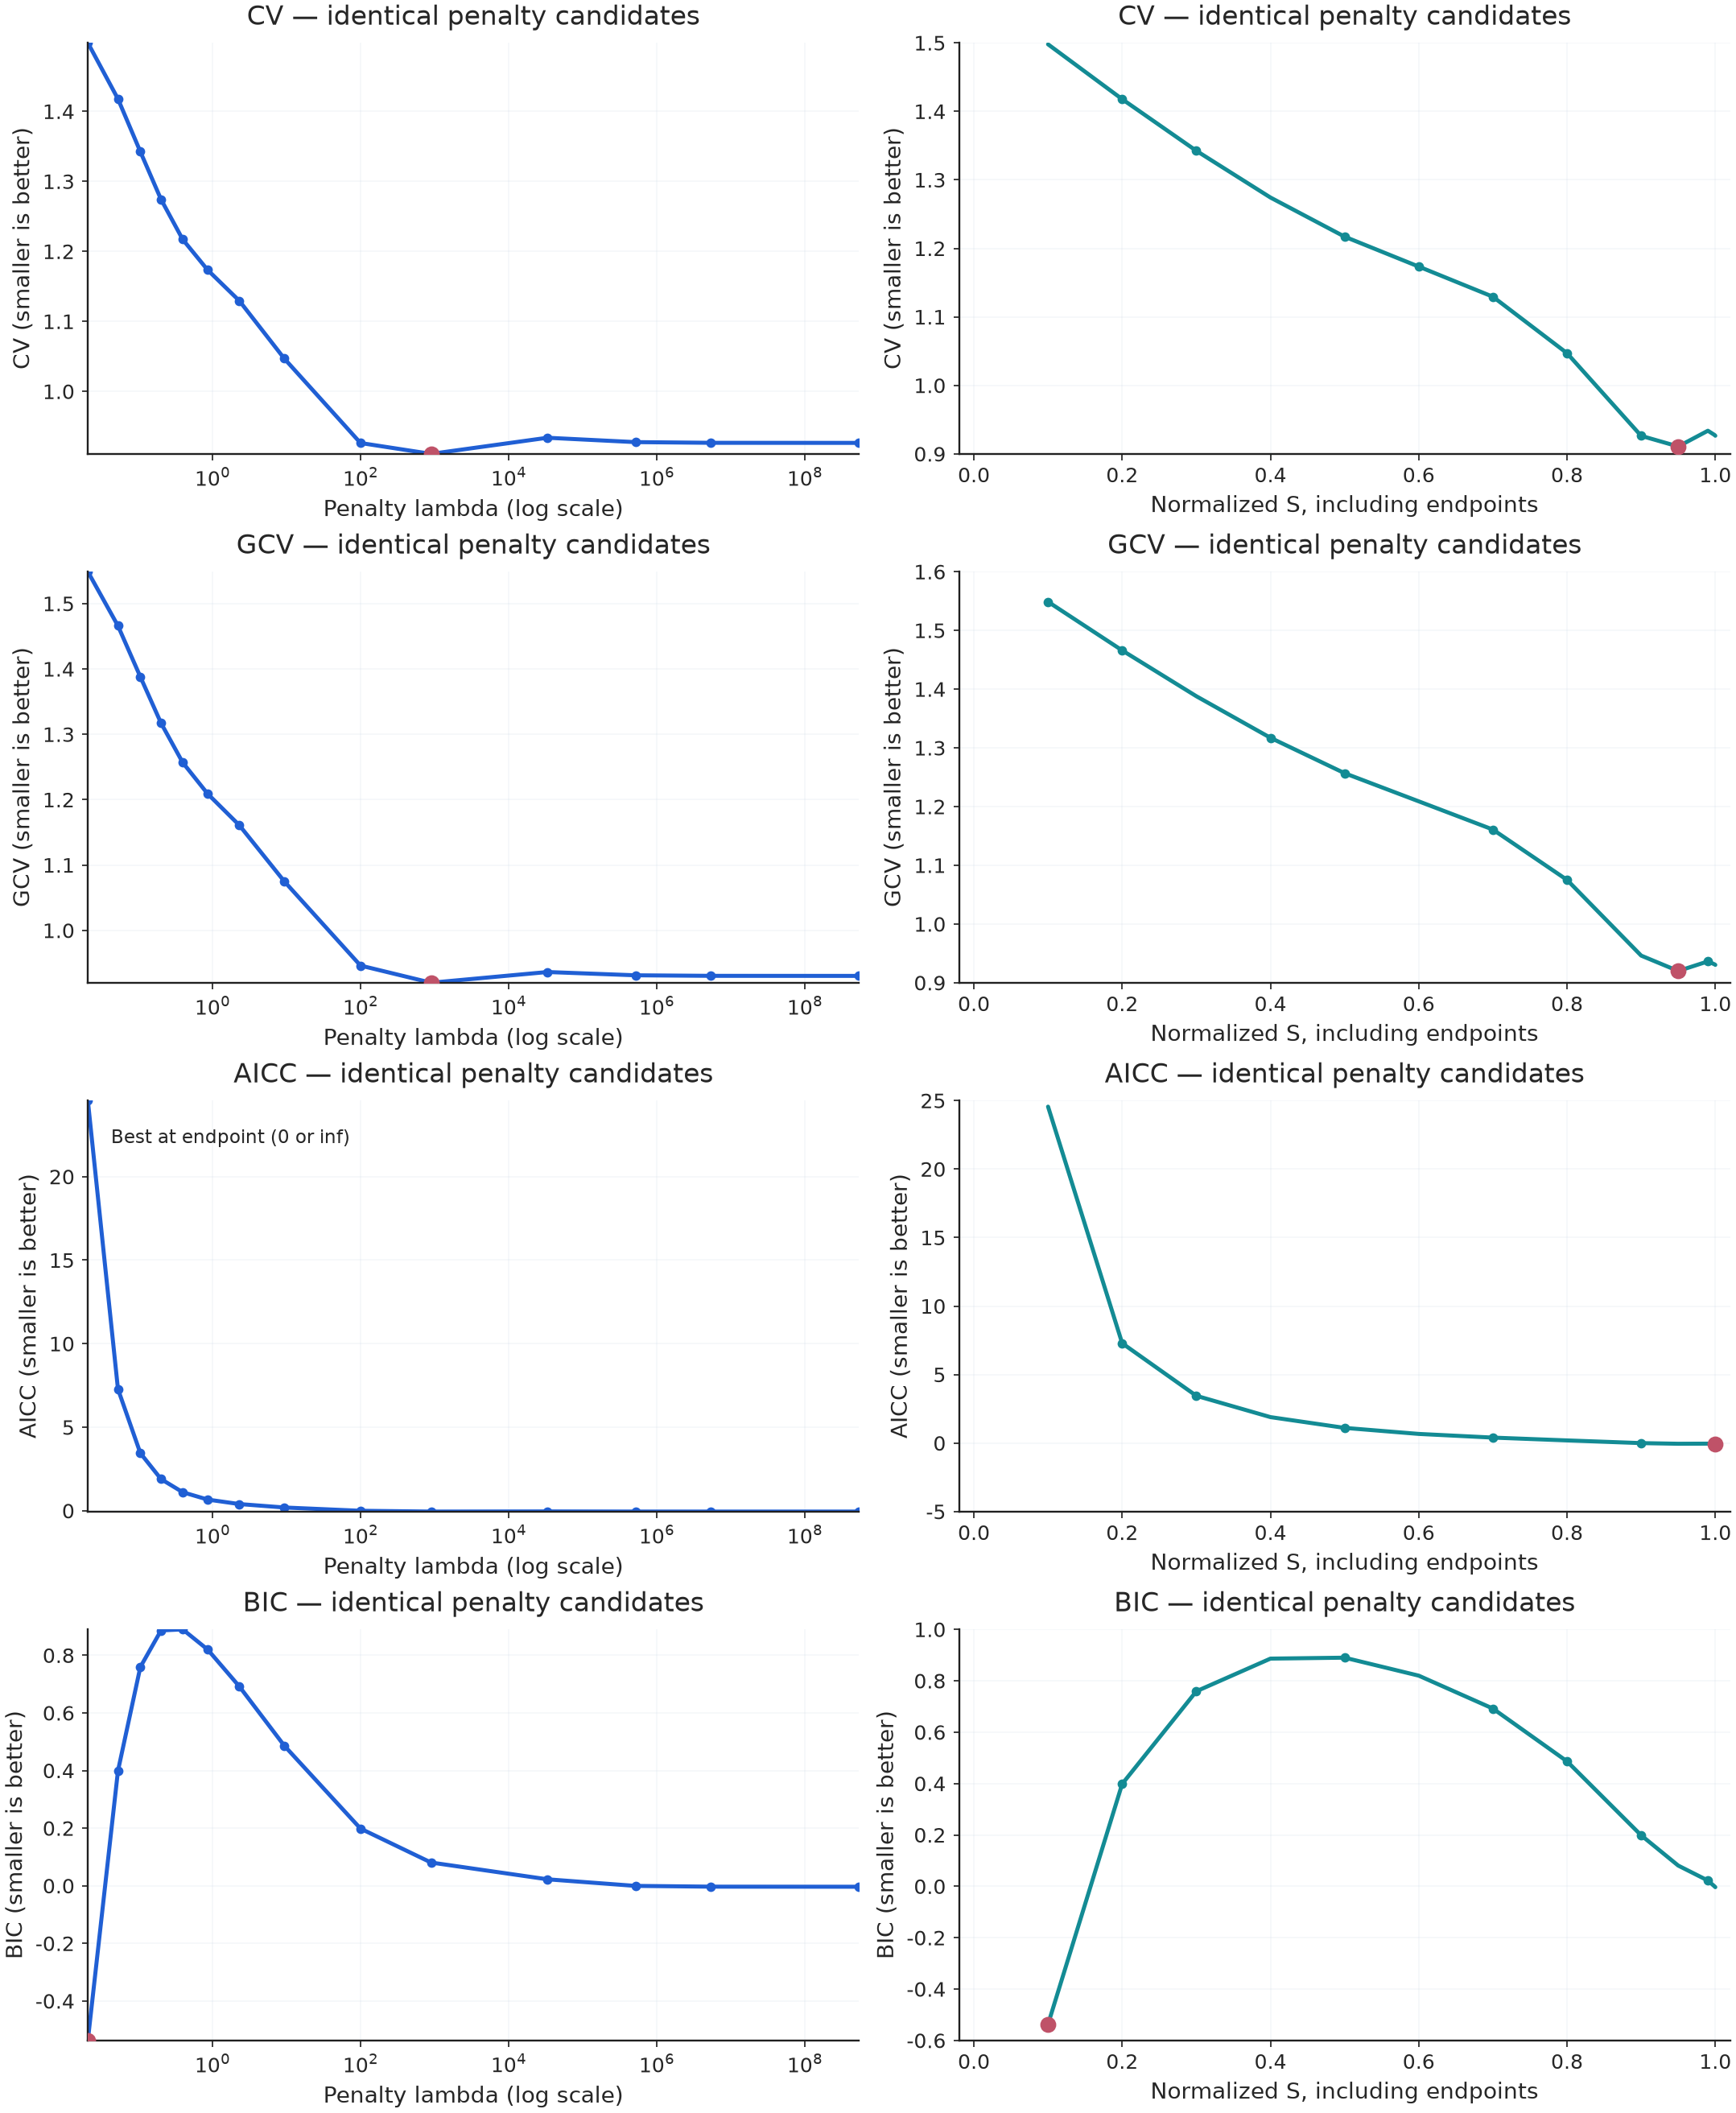

Left log-lambda plots omit 0 and infinity as coordinates, NOT as evaluated candidates. Right S plots include those endpoints. CV can be infinite at S=0 because unregularized LOOCV is undefined.


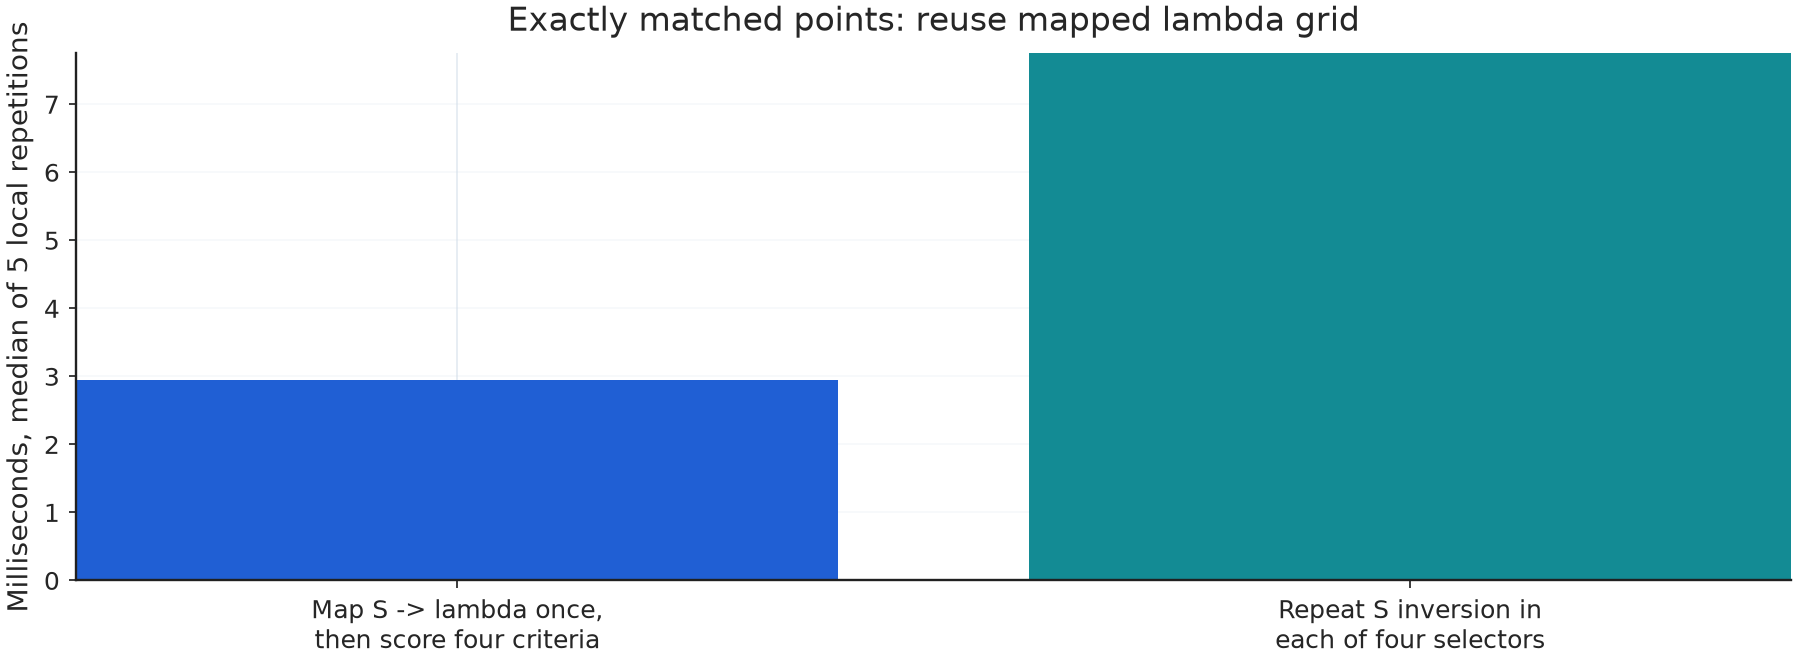

Four-criterion sweep, lambda-map-once: 2.940 ms; direct S selector (repeated mapping): 7.750 ms.
Both evaluate the same 16 penalties. This small, single-session measurement isolates a reusable-grid workflow, not the general speed of every optimization method or back end.


In [7]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
